# Setubal --> distrito 14

In [50]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_14 = pd.read_csv('df_14_d.csv')
df_14_y = pd.read_csv('df_14_y_d.csv')

df_14['ID'] = [i for i in range(len(df_14))]
df_14_y['ID'] = [i for i in range(len(df_14_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [51]:
df_14

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,1,2012,0.285714,Swimming pool,0.12,0.12,a,0.285714,0.668239,-0.081023,0
1,10,1937,0.285714,True,0.08,0.08,True,0.571429,0.668239,-0.081023,1
2,20,1969,0.285714,True,0.08,0.08,f,0.428571,0.668239,-0.081023,2
3,27,True,0.285714,Garden,0.08,0.08,d,0.571429,0.672846,-0.079300,3
4,35,True,0.071429,True,0.08,0.08,True,0.571429,0.671664,-0.079485,4
...,...,...,...,...,...,...,...,...,...,...,...
280,4419,True,0.285714,Air conditioning,0.12,0.12,c,0.428571,0.670901,-0.081686,280
281,4429,True,0.428571,Swimming pool,0.12,0.12,e,0.571429,0.668239,-0.081023,281
282,4462,1987,0.214286,True,0.10,0.06,d,0.428571,0.672191,-0.081692,282
283,4477,True,0.214286,Garden,0.06,0.06,e,0.571429,0.672078,-0.081743,283


# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

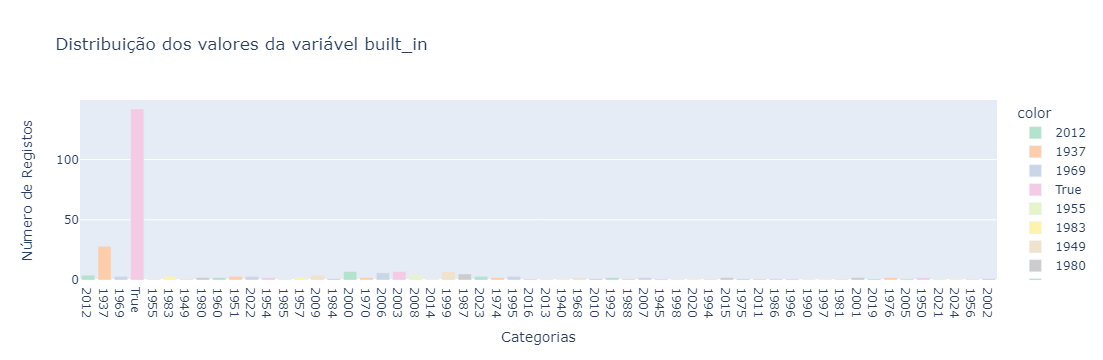

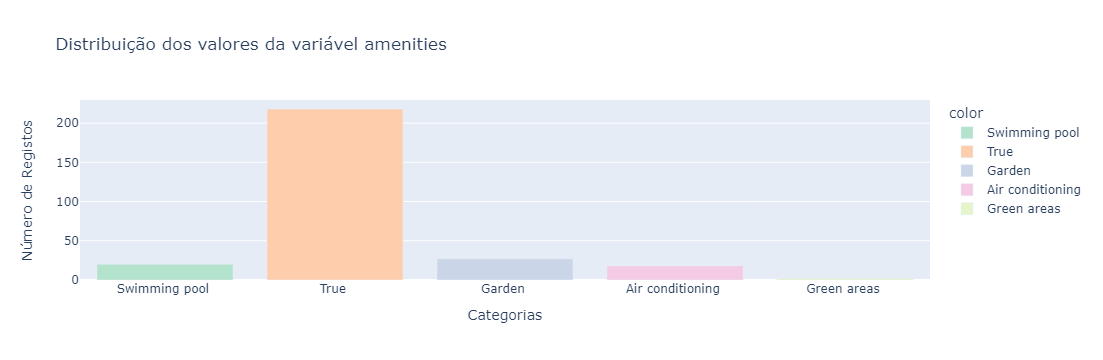

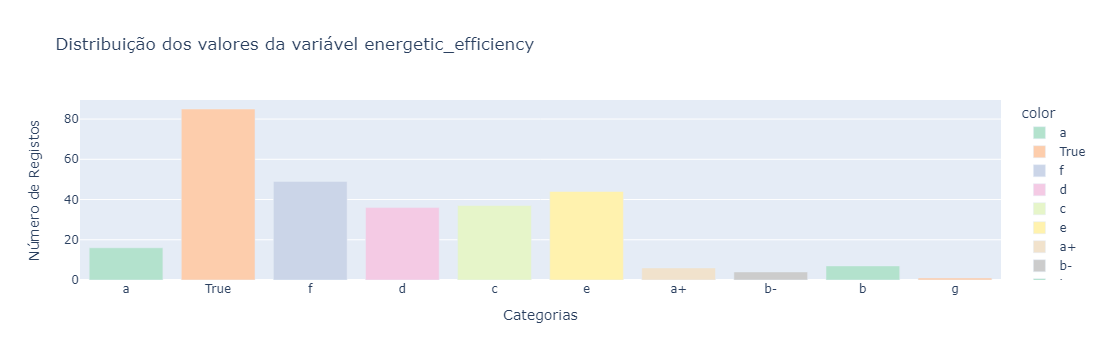

In [52]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_14[nome].unique()
    for i in df_14[nome].unique():
        bt2 = df_14[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_14, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [53]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true14 = list(df_14.loc[df_14['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_g14 = list(df_14.loc[df_14['energetic_efficiency'] == 'g', 'ID']) # como só havia 1 sample replicar 2x
ids_outros14 = list(df_14.loc[df_14['energetic_efficiency'] != 'True', 'ID'])

# Como há elementos só com 1 elemento meter mais 2 --> replicar
ids_outros14.append(ids_g14[0])
ids_outros14.append(ids_g14[0])

# Dados 
teste14 = df_14.loc[ids_true14,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y14 = df_14.loc[ids_true14,['energetic_efficiency']]
treino14 = df_14.loc[ids_outros14,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y14 = df_14.loc[ids_outros14,['energetic_efficiency']]

# Comparação --> X_train_13[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee14 = KNN(3, teste14, treino14, treino_y14)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_14 = sub_ee(ids_true14, l_ee14, df_14, 'energetic_efficiency')


ee14 = df_14.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee14 = substituir_energetic_efficiency(ee14)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee14 = norm_ee(ee14)

df_14['energetic_efficiency'] = ee14

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [54]:
aa14 = df_14.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa14 = substituir_amenities(aa14)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa14 = norm_amenities(aa14)

df_14['amenities'] = aa14

### --> built_in

In [55]:
id_true14 = list(df_14.loc[df_14['built_in'] == 'True', 'ID'])
id_outros14 = list(df_14.loc[df_14['built_in'] != 'True', 'ID'])

# Anos que só têm 1 sample --> meter + duas
lista_data14 = ['1955', '1949', '1980','1960', '1951', '2022', '1954','1985', '1957','1984', '1970', '2014', '1974', '1995', '2016', '2013', '1940', '1968', 
              '2010','1992', '1988', '2007', '1945', '1998', '2020', '1994', '2015', '1975', '2011', '1986', '1996', '1990''1997', '1981', '2001', '2019', 
              '1976', '2005','1950', '2021', '2024', '1956', '2002']

for ano in lista_data14: 
    id_ano = list(df_14.loc[df_14['built_in'] == ano, 'ID'])
    for i in range(len(id_ano)):
        id_outros14.append(id_ano[i])
        id_outros14.append(id_ano[i])

# Dados 
# criar dataset com price

d_b14 =  df_14.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_214 = df_14_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b14 = d_b14.join(d_b_214)


teste_b14 = d_b14.loc[id_true14,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y14 = df_14.loc[ids_true14,['built_in']]
treino_b14 = d_b14.loc[id_outros14,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y14 = df_14.loc[id_outros14,['built_in']]

# KNN
l_b_i14 = KNN(3, teste_b14, treino_b14, treino_b_y14)

# Substituir
df_14 = sub_ee(id_true14, l_b_i14, df_14, 'built_in')

b_i14 = df_14.loc[:, ['built_in']]
b_i14['built_in'] = b_i14['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i14 = norm_b_i(b_i14)

df_14['built_in'] = b_i14

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [56]:
df_14

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,1,0.994071,0.285714,0.363636,0.12,0.12,0.222222,0.285714,0.668239,-0.081023,0
1,10,0.957016,0.285714,0.090909,0.08,0.08,0.888889,0.571429,0.668239,-0.081023,1
2,20,0.972826,0.285714,0.090909,0.08,0.08,0.888889,0.428571,0.668239,-0.081023,2
3,27,0.957016,0.285714,0.272727,0.08,0.08,0.666667,0.571429,0.672846,-0.079300,3
4,35,0.957016,0.071429,0.090909,0.08,0.08,0.777778,0.571429,0.671664,-0.079485,4
...,...,...,...,...,...,...,...,...,...,...,...
280,4419,0.987648,0.285714,0.181818,0.12,0.12,0.555556,0.428571,0.670901,-0.081686,280
281,4429,0.984190,0.428571,0.363636,0.12,0.12,0.777778,0.571429,0.668239,-0.081023,281
282,4462,0.981719,0.214286,0.090909,0.10,0.06,0.666667,0.428571,0.672191,-0.081692,282
283,4477,0.957016,0.214286,0.272727,0.06,0.06,0.777778,0.571429,0.672078,-0.081743,283


# Modelo

In [57]:

# Dividir em treino e teste

X_train_14, X_test_14, y_train_14, y_test_14 = train_test_split(df_14, df_14_y, test_size=0.15, random_state=42)
X_train_14

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
132,2234,0.957016,0.214286,0.090909,0.12,0.12,0.777778,0.142857,0.668532,-0.081783,132
73,1384,0.968379,0.285714,0.090909,0.10,0.10,0.888889,0.428571,0.687649,-0.080098,73
202,3350,0.992095,0.285714,0.090909,0.30,0.18,0.333333,0.142857,0.679002,-0.077804,202
224,3701,0.981719,0.285714,0.090909,0.12,0.08,0.777778,0.571429,0.668239,-0.081023,224
246,3922,1.000000,0.214286,0.181818,0.16,0.16,0.111111,1.000000,0.667315,-0.081869,246
...,...,...,...,...,...,...,...,...,...,...,...
188,3053,0.957016,0.285714,0.090909,0.12,0.12,0.777778,0.571429,0.668239,-0.081023,188
71,1313,0.972826,0.142857,0.090909,0.36,0.16,0.888889,0.571429,0.673023,-0.079178,71
106,1774,0.992589,0.285714,0.181818,0.12,0.12,0.555556,0.428571,0.671173,-0.081635,106
270,4248,0.957016,0.285714,0.272727,0.10,0.10,0.888889,0.571429,0.671290,-0.080815,270


In [58]:
X_train14 = X_train_14[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test14 = X_test_14[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train14 = y_train_14[['Price_norm']]
y_test14 = y_test_14[['Price_norm']]

# MLPRegressor

In [60]:
# Melhor segundo GridSearchCV --< colab

"""
regr = MLPRegressor(hidden_layer_sizes=(150,), activation='relu',  solver='lbfgs',alpha=0.005, learning_rate= 'adaptive', learning_rate_init = 0.1,  tol = 0.0001, max_iter=800).fit(X_train14, y_train14)
y_pred = regr.predict(X_test14)
y_pred = [abs(x) for x in y_pred]
print(y_pred)
print(mean_squared_error(y_pred,y_test14))
print(regr.score(X_test14, y_test14))


### Guardar o modelo

import pickle

with open('modelo_dist14.pkl', 'wb') as file:
    pickle.dump(regr, file)
"""

[0.043056608717245246, 0.07630921914961399, 0.058569740853563854, 0.06962152768649803, 0.013145454704034595, 0.01060468587018304, 0.0118858214405589, 0.015445289835350637, 0.03934571783665124, 0.0313910207751182, 0.1897664011032819, 0.011598484317148022, 0.02874191040833156, 0.0657431211849749, 0.002888586865539375, 0.10946460859881747, 0.028681161877315856, 0.06620574113965795, 0.051175847006511524, 0.0657431211849749, 0.05101325737034883, 0.02319687652043527, 0.017268019090913245, 0.06734000018228621, 0.01617628780146506, 0.05079884409299272, 0.07365680836628404, 0.035735165436289365, 0.010295749424023296, 0.004829532283861418, 0.015483824173036578, 0.03077528909917189, 0.013127966222084342, 0.0476574129790731, 0.031900088736646084, 0.06299193121936282, 0.0657431211849749, 0.06734000018228621, 0.015879893510722734, 0.015353610269311993, 0.02643844332615279, 0.021927361395942785, 0.03439469376649733]
0.000786475692875826
0.3831905125411693


C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1625: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



In [61]:
regr.score(X_test14, y_test14) # não é um score muito alto.....

0.3831905125411693

In [62]:
# abrir modelo

with open('modelo_dist14.pkl', 'rb') as f:
    MLR = pickle.load(f)
MLR

MLPRegressor(alpha=0.005, hidden_layer_sizes=(150,), learning_rate='adaptive',
             learning_rate_init=0.1, max_iter=800, solver='lbfgs')

In [63]:
y_prev = MLR.predict(X_test14)

# OUTPUT E VIS

In [64]:
y_test14['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_7872\3625068982.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [65]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test14['Price_prev'] = lista_des(y_prev)


def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test14 = df_criar_id(y_test14, df_14_y)

C:\Users\User\AppData\Local\Temp\ipykernel_7872\4171448958.py:12: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_7872\4171448958.py:18: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_7872\4171448958.py:18: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_787

In [66]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test14 =  intervalo_preco(y_test14)

In [67]:
y_test14

,Price_norm,prev_norm,Price_prev,Price_Real,Price_Prev_Int
9,0.025333,0.043057,645849.0,380000,"[626473.53, 665224.47]"
249,0.076667,0.076309,1144638.0,1150000,"[1110298.86, 1178977.14]"
157,0.010267,0.058570,878546.0,154000,"[852189.62, 904902.38]"
209,0.093333,0.069622,1044323.0,1400000,"[1012993.31, 1075652.69]"
75,0.015333,0.013145,197182.0,230000,"[191266.54, 203097.46]"
232,0.008667,0.010605,159070.0,130000,"[154297.9, 163842.1]"
264,0.021333,0.011886,178287.0,320000,"[172938.39, 183635.61]"
170,0.015333,0.015445,231679.0,230000,"[224728.63, 238629.37]"
42,0.016567,0.039346,590186.0,248500,"[572480.42, 607891.58]"
225,0.014333,0.031391,470865.0,215000,"[456739.05, 484990.95]"


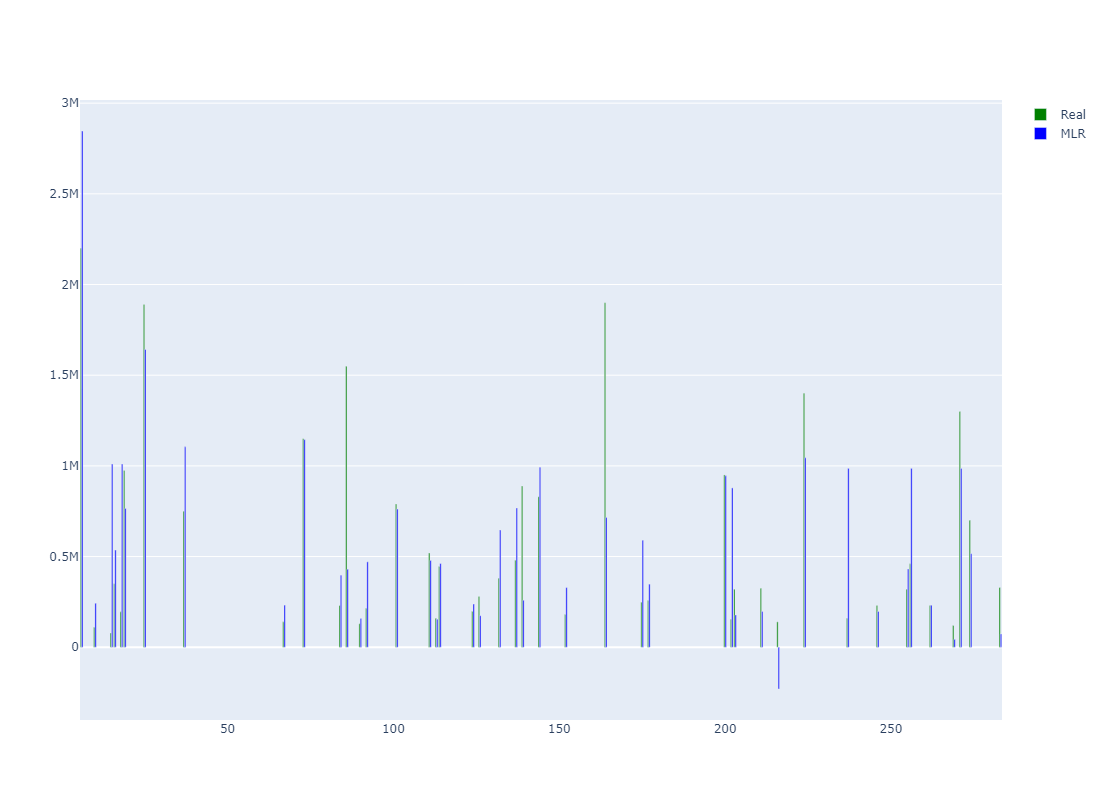

In [68]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_14.ID, y=y_test14.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_14.ID, y=y_test14.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()